## Project title: # EV Charging Demand Forecasting Using Time Series Modeling
## Goal: # Predict future electricity consumption in kWh using historical charging station data.
## Tools: # Python, Pandas, NumPy, Matplotlib, Scikit-learn, Streamlit and Excel.


## Project will predict future EV charging electricity demand using time series analysis and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

df = pd.read_csv("project_dataset_EV_charging_v-sem(project_dataset_EV_charging_v-s).csv")
df.head()

,Timestamp,Station_ID,Location,Charging_Sessions,Energy_Consumed_kWh,Charging_Duration_min,Avg_Charging_Power_kW,Temperature_C,Humidity_%,Day_of_Week,Hour,Is_Weekend
0,9/1/2026 0:00,ST-001,Downtown Plaza,0,0.00,0.00,0.00,20.47,76.8,Tuesday,0,False
1,9/1/2026 1:00,ST-001,Downtown Plaza,0,0.00,0.00,0.00,18.69,75.9,Tuesday,1,False
2,9/1/2026 2:00,ST-001,Downtown Plaza,0,0.00,0.00,0.00,20.30,76.1,Tuesday,2,False
3,9/1/2026 3:00,ST-001,Downtown Plaza,0,0.00,0.00,0.00,19.09,80.8,Tuesday,3,False
4,9/1/2026 4:00,ST-001,Downtown Plaza,2,50.02,39.43,76.13,17.57,81.0,Tuesday,4,False


In [2]:
df.shape

(3600, 12)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Timestamp              3600 non-null   object 
 1   Station_ID             3600 non-null   object 
 2   Location               3600 non-null   object 
 3   Charging_Sessions      3600 non-null   int64  
 4   Energy_Consumed_kWh    3600 non-null   float64
 5   Charging_Duration_min  3600 non-null   float64
 6   Avg_Charging_Power_kW  3600 non-null   float64
 7   Temperature_C          3600 non-null   float64
 8   Humidity_%             3600 non-null   float64
 9   Day_of_Week            3600 non-null   object 
 10  Hour                   3600 non-null   int64  
 11  Is_Weekend             3600 non-null   bool   
dtypes: bool(1), float64(5), int64(2), object(4)
memory usage: 313.0+ KB


In [4]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"],errors="coerce")
df[["Timestamp","Station_ID"]].head()

,Timestamp,Station_ID
0,2026-09-01 00:00:00,ST-001
1,2026-09-01 01:00:00,ST-001
2,2026-09-01 02:00:00,ST-001
3,2026-09-01 03:00:00,ST-001
4,2026-09-01 04:00:00,ST-001


In [5]:
df = df.sort_values(["Timestamp","Station_ID"]).reset_index(drop=True)

In [6]:
df.head()

,Timestamp,Station_ID,Location,Charging_Sessions,Energy_Consumed_kWh,Charging_Duration_min,Avg_Charging_Power_kW,Temperature_C,Humidity_%,Day_of_Week,Hour,Is_Weekend
0,2026-09-01,ST-001,Downtown Plaza,0,0.00,0.00,0.00,20.47,76.8,Tuesday,0,False
1,2026-09-01,ST-002,Airport Terminal 2,2,67.83,53.77,75.69,19.82,78.8,Tuesday,0,False
2,2026-09-01,ST-003,Westfield Mall,0,0.00,0.00,0.00,19.77,72.6,Tuesday,0,False
3,2026-09-01,ST-004,I-90 Highway Rest Stop,2,49.57,39.22,75.85,18.94,80.0,Tuesday,0,False
4,2026-09-01,ST-005,Riverside Office Park,0,0.00,0.00,0.00,19.59,80.1,Tuesday,0,False


In [7]:
df.describe()

,Timestamp,Charging_Sessions,Energy_Consumed_kWh,Charging_Duration_min,Avg_Charging_Power_kW,Temperature_C,Humidity_%,Hour
count,3600,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000,3600.000000
mean,2026-09-15 23:30:00,3.931667,129.858042,206.559697,41.652003,20.481575,73.898417,11.500000
min,2026-09-01 00:00:00,0.000000,0.000000,0.000000,0.000000,9.550000,56.200000,0.000000
25%,2026-09-08 11:45:00,1.000000,17.585000,40.937500,5.737500,16.950000,69.500000,5.750000
50%,2026-09-15 23:30:00,3.000000,73.995000,146.215000,58.840000,20.620000,73.800000,11.500000
75%,2026-09-23 11:15:00,6.000000,205.362500,293.725000,73.780000,24.010000,78.200000,17.250000
max,2026-09-30 23:00:00,21.000000,860.340000,1619.970000,118.410000,32.650000,93.200000,23.000000
std,NaN,3.601781,144.610209,220.059718,35.804153,4.597735,6.038924,6.923148


## Station Demand

In [8]:
station_demand = ( 
    df.groupby("Station_ID")["Energy_Consumed_kWh"]
    .sum()
    .sort_values(ascending = False) 
)

print(station_demand)

Station_ID
ST-002    182982.82
ST-004    131582.09
ST-001     98345.74
ST-003     36394.45
ST-005     18183.85
Name: Energy_Consumed_kWh, dtype: float64


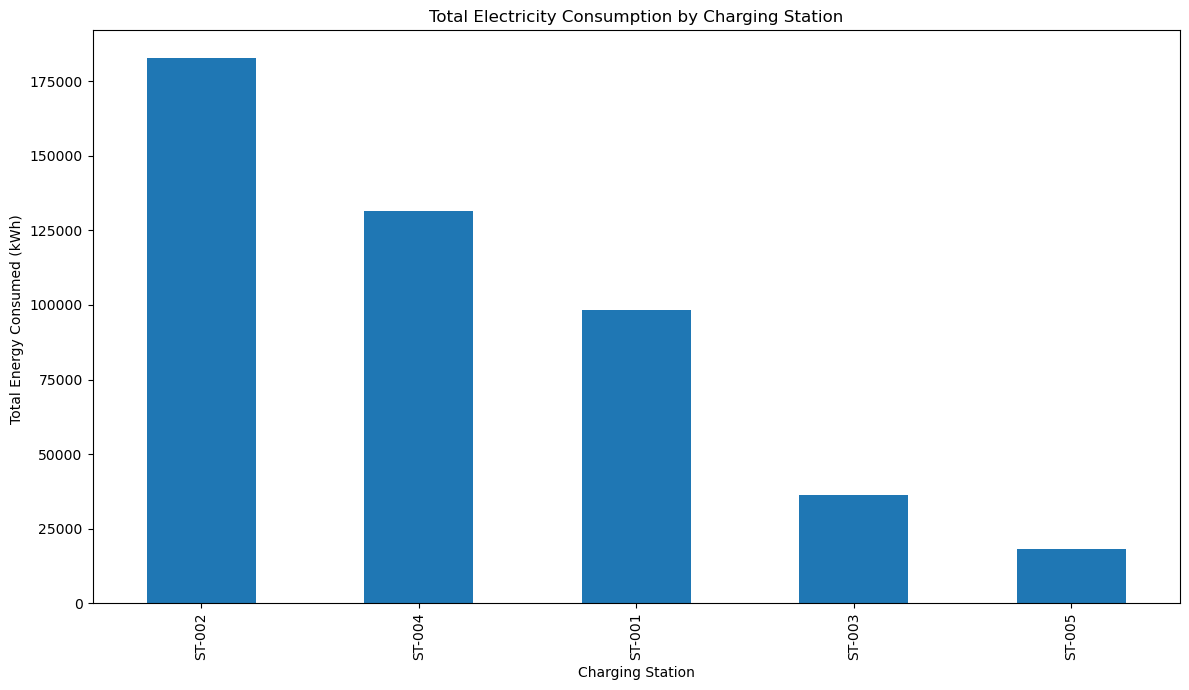

In [9]:
station_demand.plot(
    kind="bar",
    figsize=(12,7),
)
plt.title("Total Electricity Consumption by Charging Station")
plt.xlabel("Charging Station")
plt.ylabel("Total Energy Consumed (kWh) ")
plt.tight_layout()
plt.show()

## Hourly Demand  

In [10]:
hourly_demand_pattern = (
    df.groupby("Hour")["Energy_Consumed_kWh"]
    .mean()
)

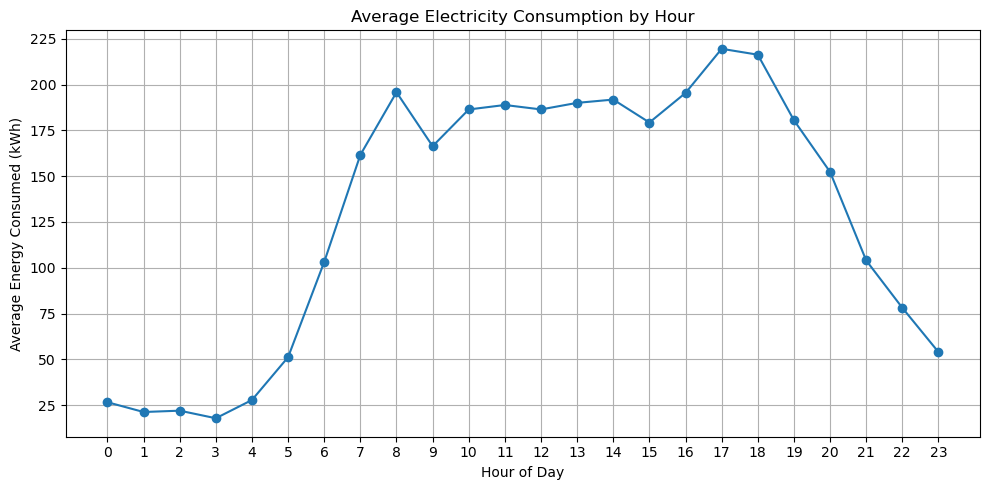

In [11]:
hourly_demand_pattern.plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumed (kWh)")
plt.xticks(range(0,24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
network_demand = (
    df.groupby("Timestamp")
    .agg({
        "Energy_Consumed_kWh": "sum",
        "Charging_Sessions": "sum",
        "Temperature_C": "mean",
        "Humidity_%": "mean",
        "Is_Weekend": "max"
    })
    .sort_index()
)

network_demand.index.name = "Timestamp"

print("Network demand shape:", network_demand.shape)

network_demand.head()

Network demand shape: (720, 5)


,Energy_Consumed_kWh,Charging_Sessions,Temperature_C,Humidity_%,Is_Weekend
Timestamp,,,,,
2026-09-01 00:00:00,117.40,4,19.718,77.66,False
2026-09-01 01:00:00,103.67,3,19.428,78.64,False
2026-09-01 02:00:00,62.32,2,18.756,78.58,False
2026-09-01 03:00:00,114.87,3,18.802,80.42,False
2026-09-01 04:00:00,107.93,4,17.786,80.02,False


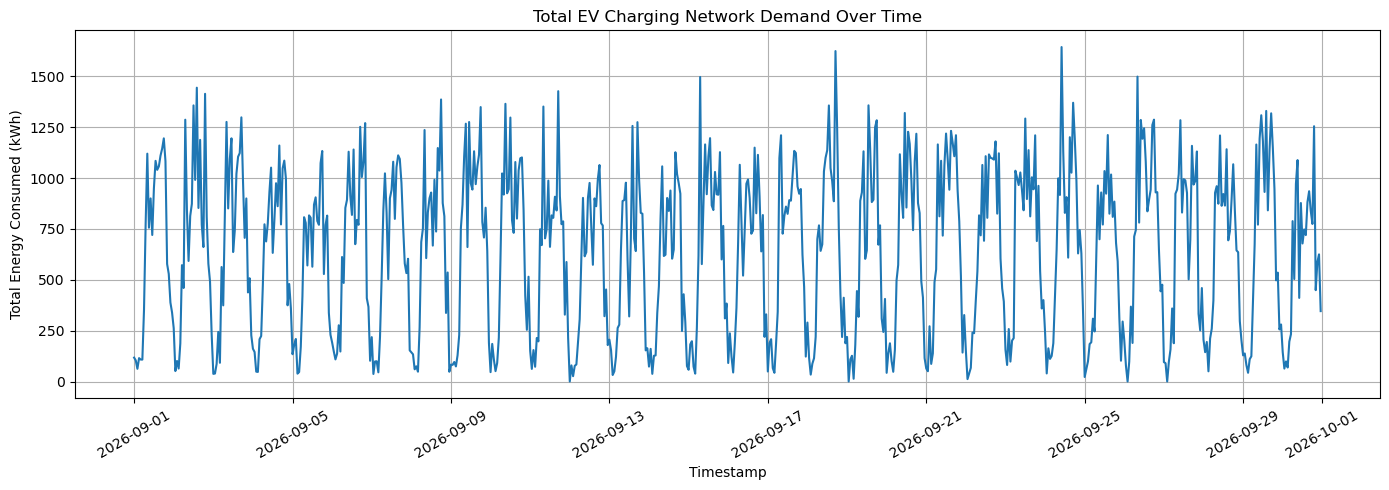

In [13]:
plt.figure(figsize=(14,5))

plt.plot(
    network_demand.index,
    network_demand["Energy_Consumed_kWh"]
)

plt.title("Total EV Charging Network Demand Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Total Energy Consumed (kWh)")

plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# create features for machine learning

model_data = network_demand.copy()
target = "Energy_Consumed_kWh"

# for 1 hour Demand
model_data["hrs_1"] = model_data[target].shift(1)
# for 24 hours demand
model_data["hrs_24"] = model_data[target].shift(24)
# for 168 hours demand
model_data["hrs_168"] = model_data[target].shift(168)

# Average demand over previous 24 hours
model_data["avg_demand_24"] = (
    # calculate avg of previous 24 observations
    model_data[target]
    .shift(1)
    .rolling(window=24)
    .mean()
)

# Time-based features
model_data["hour"] = model_data.index.hour

model_data["day_of_week"] = model_data.index.dayofweek

model_data["is_weekend"] = (
    model_data["day_of_week"] >= 5
).astype(int)

# Remove rows without sufficient historical information
model_data = model_data.dropna()

model_data.head()

,Energy_Consumed_kWh,Charging_Sessions,Temperature_C,Humidity_%,Is_Weekend,hrs_1,hrs_24,hrs_168,avg_demand_24,hour,day_of_week,is_weekend
Timestamp,,,,,,,,,,,,
2026-09-08 00:00:00,143.32,4,17.928,74.96,False,153.17,218.07,117.40,625.753333,0,1,0
2026-09-08 01:00:00,133.67,3,16.396,84.12,False,143.32,37.05,103.67,622.638750,1,1,0
2026-09-08 02:00:00,59.99,2,16.572,79.32,False,133.67,98.62,62.32,626.664583,2,1,0
2026-09-08 03:00:00,74.65,2,17.152,79.46,False,59.99,99.59,114.87,625.055000,3,1,0
2026-09-08 04:00:00,48.36,3,17.642,77.68,False,74.65,45.20,107.93,624.015833,4,1,0


In [15]:
features = [
    "hrs_1",
    "hrs_24",
    "hrs_168",
    "avg_demand_24",
    "hour",
    "day_of_week",
    "is_weekend"
]
x = model_data[features]

y = model_data[target]

#We will use approximately 80% of the available observations for training and 20% for testing.
split_index = int(len(model_data)*0.8)

x_train = x.iloc[:split_index]
x_test = x.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(x_train))
print("Testing records:", len(x_test))

print(
    "Training period:",
    x_train.index.min(),
    "to",
    x_train.index.max()
)

print(
    "Testing period:",
    x_test.index.min(),
    "to",
    x_test.index.max()
)

Training records: 441
Testing records: 111
Training period: 2026-09-08 00:00:00 to 2026-09-26 08:00:00
Testing period: 2026-09-26 09:00:00 to 2026-09-30 23:00:00


## Random Forest Regressor machine learning model

In [16]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

#teaches the model relationships between historical demand, time features, and actual electricity consumption.
model.fit(x_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## After training the model comparing its predictions with actual demand.

## Evaluate the Forecasting Model 

In [17]:
y_predict = model.predict(x_test)

MAE = mean_absolute_error(y_test , y_predict)

RMSE = np.sqrt(mean_squared_error(y_test,y_predict))

R2 = r2_score(y_test,y_predict)

print("Model Evaluation Result")

print(f"MAE: {MAE:.3f} kWh")
print(f"RMSE: {RMSE:3f} kWh")
print(f"R2: {R2:3f}")

Model Evaluation Result
MAE: 147.860 kWh
RMSE: 188.800223 kWh
R2: 0.768871


## Compare Actual and Predicted Demand

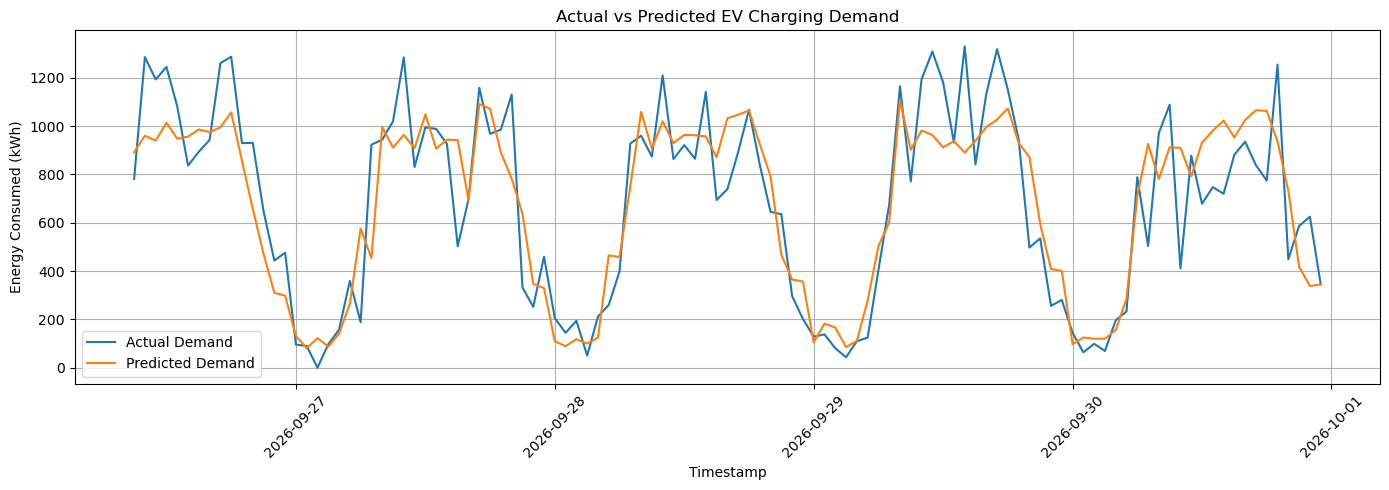

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Demand"
)

plt.plot(
    y_test.index,
    y_predict,
    label="Predicted Demand"
)

plt.title("Actual vs Predicted EV Charging Demand")
plt.xlabel("Timestamp")
plt.ylabel("Energy Consumed (kWh)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Compare Random Forest with a Simple Baseline

In [19]:
baseline_predictions = model_data[target].shift(24).loc[y_test.index]

baseline_MAE = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_RMSE = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

print("Seasonal Naive Baseline")
print(f"MAE : {baseline_MAE:3f} kWh")
print(f"RMSE : {baseline_RMSE:3f} kWh")

print("Random Forest")
print(f"MAE: {MAE:3f} kWh")
print(f"RMSE: {RMSE:3f} kWh")

Seasonal Naive Baseline
MAE : 192.140180 kWh
RMSE : 249.232258 kWh
Random Forest
MAE: 147.860394 kWh
RMSE: 188.800223 kWh


## Random Forest has lower MAE and therefore produces more accurate predictions on the test period.

# Station-wise Demand next 24 hours

In [20]:
stations = df["Station_ID"].unique()

print("Available Stations:", stations)

Available Stations: ['ST-001' 'ST-002' 'ST-003' 'ST-004' 'ST-005']


In [21]:
def prepare_station_data(station_df):

    station_df = station_df.copy()

    station_df = station_df.sort_values("Timestamp")

    station_df = station_df.set_index("Timestamp")

    # Historical demand
    station_df["Previous_Hour"] = (
        station_df["Energy_Consumed_kWh"].shift(1)
    )

    station_df["Previous_Day"] = (
        station_df["Energy_Consumed_kWh"].shift(24)
    )

    station_df["Previous_Week"] = (
        station_df["Energy_Consumed_kWh"].shift(168)
    )

    # Rolling average
    station_df["Average_Demand"] = (
        station_df["Energy_Consumed_kWh"]
        .shift(1)
        .rolling(24)
        .mean()
    )

    # Time features
    station_df["Hour"] = station_df.index.hour

    station_df["Day"] = station_df.index.dayofweek

    station_df["Month"] = station_df.index.month

    station_df["Weekend"] = (
        station_df["Day"] >= 5
    ).astype(int)

    return station_df.dropna()

## Forecasting ALL Stations

In [22]:
from sklearn.ensemble import GradientBoostingRegressor

models = {}

evaluation_results = []

features = [
    "Previous_Hour",
    "Previous_Day",
    "Previous_Week",
    "Average_Demand",
    "Hour",
    "Day",
    "Month",
    "Weekend"
]

for station in stations:

    print("\nTraining:", station)

    # Select individual station
    station_df = df[df["Station_ID"] == station].copy()

    # Prepare features
    station_df = prepare_station_data(station_df)

    X = station_df[features]

    y = station_df["Energy_Consumed_kWh"]

    # Chronological split
    split = int(len(station_df) * 0.8)

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    y_train = y.iloc[:split]
    y_test = y.iloc[split:]

    # Create model
    model = GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Evaluation
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    models[station] = model

    evaluation_results.append({
        "Station": station,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2:", round(r2, 3))


Training: ST-001
MAE: 66.698
RMSE: 87.738
R2: 0.449

Training: ST-002
MAE: 117.974
RMSE: 157.976
R2: 0.274

Training: ST-003
MAE: 24.87
RMSE: 35.564
R2: 0.565

Training: ST-004
MAE: 78.986
RMSE: 106.015
R2: 0.439

Training: ST-005
MAE: 16.834
RMSE: 21.962
R2: 0.111


In [23]:
future_forecasts = []

for station in stations:

    station_df = (
        df[df["Station_ID"] == station]
        .sort_values("Timestamp")
    )

    history = station_df.set_index("Timestamp")[
        "Energy_Consumed_kWh"
    ].copy()

    model = models[station]

    for i in range(24):

        next_time = history.index[-1] + pd.Timedelta(hours=1)

        row = pd.DataFrame([{
            "Previous_Hour": history.iloc[-1],
            "Previous_Day": history.iloc[-24],
            "Previous_Week": history.iloc[-168],
            "Average_Demand": history.iloc[-24:].mean(),
            "Hour": next_time.hour,
            "Day": next_time.dayofweek,
            "Month": next_time.month,
            "Weekend": int(next_time.dayofweek >= 5)
        }])

        prediction = model.predict(row[features])[0]

        prediction = max(0, prediction)

        future_forecasts.append({
            "Timestamp": next_time,
            "Station": station,
            "Predicted_Energy_kWh": prediction
        })

        history.loc[next_time] = prediction

forecast_results = pd.DataFrame(future_forecasts)

forecast_results.head(15)

,Timestamp,Station,Predicted_Energy_kWh
0,2026-10-01 00:00:00,ST-001,19.325934
1,2026-10-01 01:00:00,ST-001,27.027255
2,2026-10-01 02:00:00,ST-001,27.027255
3,2026-10-01 03:00:00,ST-001,31.532997
4,2026-10-01 04:00:00,ST-001,59.613759
5,2026-10-01 05:00:00,ST-001,52.487166
6,2026-10-01 06:00:00,ST-001,131.326967
7,2026-10-01 07:00:00,ST-001,240.401051
8,2026-10-01 08:00:00,ST-001,350.704243
9,2026-10-01 09:00:00,ST-001,217.807884


## Visualize all Five Station Forecast

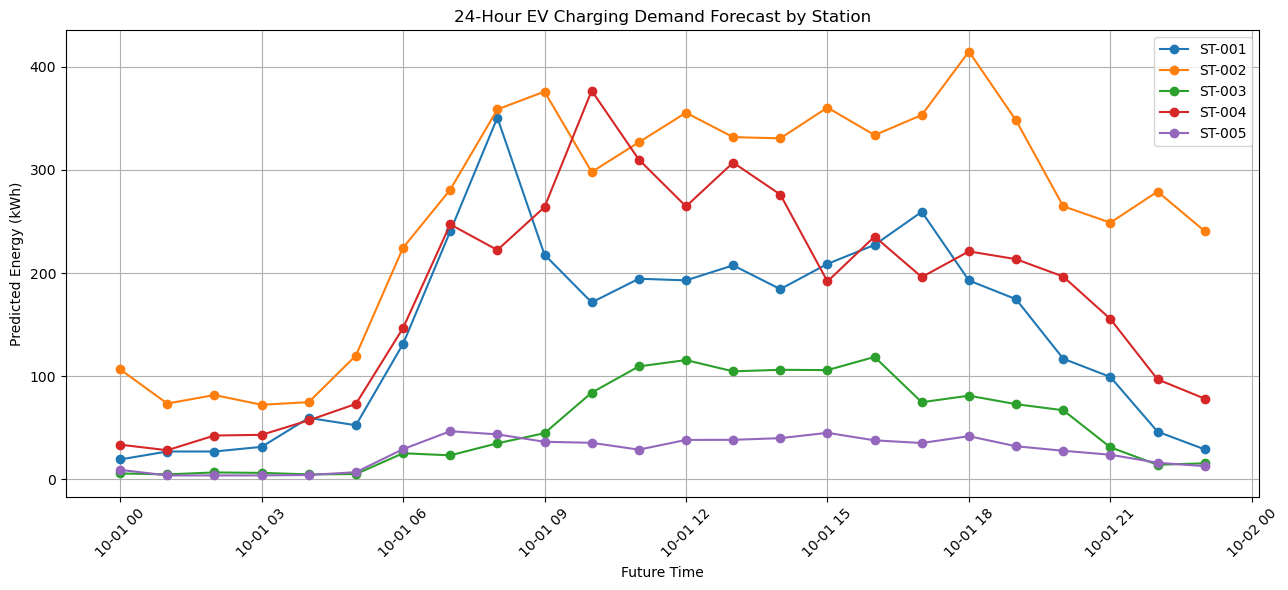

In [24]:
plt.figure(figsize=(13, 6))

for station in stations:

    temp = forecast_results[
        forecast_results["Station"] == station
    ]

    plt.plot(
        temp["Timestamp"],
        temp["Predicted_Energy_kWh"],
        marker="o",
        label=station
    )

plt.title("24-Hour EV Charging Demand Forecast by Station")

plt.xlabel("Future Time")

plt.ylabel("Predicted Energy (kWh)")

plt.legend()

plt.xticks(rotation=45)

plt.grid()

plt.tight_layout()

plt.show()

# Forecast the Next 24 Hours

In [27]:
# Start with the observed hourly demand
History = network_demand[target].copy()

future_predictions = []

# Forecast the next 24 hours
for step in range(24):

    next_timestamp = History.index[-1] + pd.Timedelta(hours=1)

    # Historical demand features
    lag_1 = History.iloc[-1]
    lag_24 = History.iloc[-24]
    lag_168 = History.iloc[-168]

    rolling_mean_24 = History.iloc[-24:].mean()

    # Time features for the next timestamp
    hour = next_timestamp.hour
    day_of_week = next_timestamp.dayofweek
    is_weekend = int(day_of_week >= 5)

    # Create input in the same order as the training features
    next_features = pd.DataFrame([{
    "Previous_Hour": History.iloc[-1],
    "Previous_Day": History.iloc[-24],
    "Previous_Week": History.iloc[-168],
    "Average_Demand": History.iloc[-24:].mean(),
    "Hour": next_timestamp.hour,
    "Day": next_timestamp.dayofweek,
    "Month": next_timestamp.month,
    "Weekend": int(next_timestamp.dayofweek >= 5)
    }])

    # Predict demand
    prediction = model.predict(next_features)[0]

    # Save forecast
    future_predictions.append({
        "Timestamp": next_timestamp,
        "Forecast_Energy_kWh": prediction
    })

    # Add prediction to history for the next iteration
    History.loc[next_timestamp] = prediction

forecast_df = pd.DataFrame(future_predictions)

forecast_df

,Timestamp,Forecast_Energy_kWh
0,2026-10-01 00:00:00,64.941842
1,2026-10-01 01:00:00,12.188845
2,2026-10-01 02:00:00,69.200100
3,2026-10-01 03:00:00,25.420789
4,2026-10-01 04:00:00,25.344469
5,2026-10-01 05:00:00,56.133766
6,2026-10-01 06:00:00,82.715636
7,2026-10-01 07:00:00,83.467120
8,2026-10-01 08:00:00,81.054515
9,2026-10-01 09:00:00,74.917522


## Plot next 24 hours

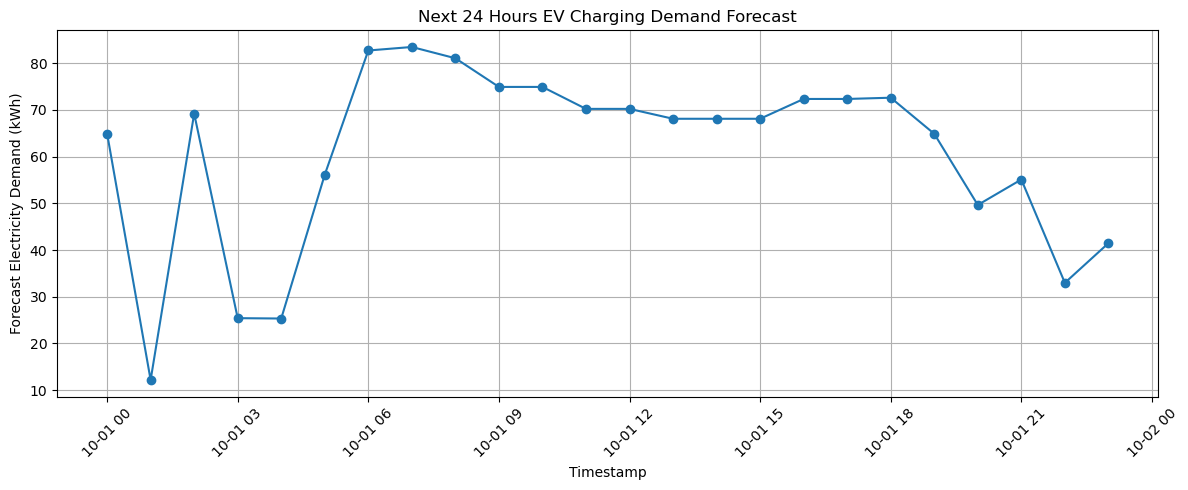

In [28]:
plt.figure(figsize = (12,5))

plt.plot(
    forecast_df["Timestamp"],
    forecast_df["Forecast_Energy_kWh"],
    marker = "o"
)

plt.title("Next 24 Hours EV Charging Demand Forecast")
plt.xlabel("Timestamp")
plt.ylabel("Forecast Electricity Demand (kWh)")

plt.xticks(rotation = 45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
forecast_df.to_csv(
    "EV_Charging_Demand_Forecast.csv",
    index=False
)

print("Forecast saved successfully!")

Forecast saved successfully!
